# Tema 7. Ejercicio de los peatones en la pandemia con visualizaciones

En este ejercicio vamos a utilizar incorporar gárficos al ejercicios de peatones hecho en el tema anterior.

Recuerda que trabajamos con el fichero .csv de la página del Portal de Datos Abiertos del Ayuntamiento de Madrid (https://datos.madrid.es/). Desde dicha página buscamos `peatones` y nos lleva a `Aforos de peatones y bicicletas` (https://datos.madrid.es/dataset/300321-0-aforos-peatones-bicicletas). Aquí tenemos que descargarnos el fichero csv de peatones correspondiente al año 2020
https://datos.madrid.es/dataset/300321-0-aforos-peatones-bicicletas/downloads.
 
 La descripción de cada campo del fichero es:

| Número de columna | Nombre columna            | Descripción                                                   | Valores esperados              |
|-------------------|---------------------------|---------------------------------------------------------------|--------------------------------|
| 1                 | fecha                     | Fecha del registro. Formato de fecha: DD-MM-AAAA.            |                                |
| 2                 | hora                      | Hora del registro. Formato de hora: HH:MM.                   |                                |
| 3                 | identificador             | Identificador único del registro.                             | Texto                          |
| 4                 | peatones                  | Número de peatones registrados.                             | Numérico                       |
| 5                 | device_id                 | Identificador único del registro.                             | Texto                          |
| 6                 | Número_distrito           | Número identificativo del distrito.                           | Numérico                       |
| 7                 | distrito                  | Nombre del distrito.                                          | Texto                          |
| 8                 | direccion                 | Dirección exacta del aforo.                                   | Texto                          |
| 9                 | observaciones_direccion   | Observaciones adicionales sobre la dirección del tráfico.     | Texto                          |
| 10                | latitude                  | Latitud geográfica del registro.                              | Número decimal (40.400000)     |
| 11                | longitude                 | Longitud geográfica del registro.                             | Número decimal (3.700000)      |



## Carga de datos y exploración del dataframe

Después de descargarnos el fichero `300321-3-aforos-peatones-bicicletas-csv.csv` correspondiente al año 2020  de la web https://datos.madrid.es/dataset/300321-0-aforos-peatones-bicicletas/downloads, lo dejamos en nuestra carpeta llamada Data y lo importamos como un dataframe llamado df.

Lo primero que tenemos que hacer es ver el contenido del fichero con una aplicación de texto plano y veo que el csv no está separado por `comas`, sino por `punto y coma` y además, utiliza la `coma` como separador decimal en LATITUD y LONGITUD. Así que se debe indicar `sep=";"` y `decimal=","` como parámetros de la carga de pandas `pd.read_csv`. 

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "./Data/300321-3-aforos-peatones-bicicletas-csv.csv",
    sep=";",
    decimal=","
)

Muestra el DataFrame para comprobar que la carga se ha realizado correctamente. Puedes escribir simplemente el nombre del objeto.

In [11]:
df.shape

(166896, 12)

## Analizar y transformar los tipos de datos

Por el trabajo del tema anterior ya sabemos que 
- `PEATONES`, `NÚMERO_DISTRITO`, `NÚMERO`y `CÓDIGO_POSTAL` son `int64`,
- `LATITUD` y `LONGITUD` son `float64`.
- resto son de tipo  object

Pero en python tenemos un tipo de datos específico para la fecha y la hora

### Fechas 
En Python podemos trabajar con distintos tipos de datos temporales:
- `date`: representa una fecha: año, mes y día.
- `time`: representa una hora: hora, minutos, segundos.
- `datetime`: representa fecha y hora conjuntamente

Usamos `pd.to_datetime()` para convertir los tipos de los valores de la columna `FECHA`. Además, necesitamos el parámetro `dayfirst = True` para indicar a pandas que, al interpretar una fecha, el primer número corresponde al día pues la fecha está escrita con el día antes del mes.

Al ejecutar `df["FECHA"] = pd.to_datetime(df["FECHA"], dayfirst=True)` da error porque el fichero hay dos formatos diferentes en las fechas, unos es con la hora `01/01/2020 00:00` y el otro es sin hora `02/09/2020`.
Pandas ha inferido inicialmente el formato `%d/%m/%Y %H:%M` pero ha detectado un valor que no seguía este formato. Pandas nos aconseja que tomemos el formato mixto para la fecha.

In [17]:
df["FECHA"] = pd.to_datetime(
    df["FECHA"],
    dayfirst = True,
    format = "mixed"
)

# comprobamos el tipo del primer valor de la columna `FECHA`
type(df["FECHA"].iloc[0])

pandas._libs.tslibs.timestamps.Timestamp

Ahora sí que estamos trabajando con fechas reales y podemos, por ejemplo, 
extraer de FECHA una parte concreta utilizando el accesor `.dt`. Prueba primero con el año (`df["FECHA"].dt.year`), después con el mes y finalmente con el nombre del día de la semana.

### Horas

Ahora vamos con la columna `HORA` que aparece como texto de la forma `00:00` y `01:00`. Estos valores
podemos convertirlos a un tipo de hora de pandas pero, pandas no tiene una función `pd.to_time()`. Necesitamos hacer un `pd.to_datetime()` con formato `%H:%M` como parámetro. Finalmente, aplicamos `pd.to_datetime().dt.time` para quedarnos únicamente con la parte de la hora.


In [21]:
df["HORA"] = pd.to_datetime(
    df["HORA"],
    format="%H:%M"
).dt.time

type(df["HORA"].iloc[0])

datetime.time

## Seleccionar ciertas columnas de la tabla, las que me interesan


Crea un nuevo DataFrame `df_1` seleccionando únicamente las columnas:
`FECHA`, `HORA`, `PEATONES`, `DISTRITO`, `NOMBRE_VIAL` y `NÚMERO`.
Para seleccionar varias columnas necesitas una lista de nombres dentro de los corchetes.
Usa `.copy()` para crear un nuevo DataFrame independiente.


In [24]:
df_1 = df[["FECHA", "HORA", "PEATONES", "DISTRITO", "NOMBRE_VIAL", "NÚMERO"]].copy()

## Cambiar el nombre de la columna `NOMBRE_VIAL`por `DIRECCIÓN`. 

Utiliza `rename()` para cambiar el nombre de `NOMBRE_VIAL` por `DIRECCIÓN`.
Después puedes consultar `df_1.columns` para comprobar el cambio.


In [27]:
df_1 = df_1.rename(columns={"NOMBRE_VIAL": "DIRECCIÓN"})
df_1.columns

Index(['FECHA', 'HORA', 'PEATONES', 'DISTRITO', 'DIRECCIÓN', 'NÚMERO'], dtype='object')

## Estudio de los peatones

### Gráfico: pie chart

No tiene sentido hacer un pie chart Con las variables de las columnas de forma simple `FECHA`, `HORA`, `PEATONES`, `DISTRITO`, `DIRECCIÓN`y `NÚMERO`, pero sí que tiene sentido hacer un gráfico pie chart que represente *qué porcentaje del total de peatones registrados corresponde a cada distrito*. Por lo tanto, necesitamos hacer un groupby que sume los `PEATONES` de cada `DISTRITO`.

In [67]:
peatones_distrito = df_1.groupby("DISTRITO")["PEATONES"].sum()
peatones_distrito

DISTRITO
Arganzuela          3346568
Centro             35746458
Chamberí            2908708
Latina               858100
Moncloa-Aravaca     3283849
Name: PEATONES, dtype: int64

Como vemos `peatones_distrito` es una *Serie* que contiene los totales y cuyos índices son los nombres de los distritos. Así, 
- `peatones_distrito.value` es una una secuencia de valores numéricos utilizados para calcular el tamaño de cada sector.
- `peatones_distrito.index` son los nombres de los distritos que usamos como etiquetas de los sectores. 

In [70]:
peatones_distrito.values

array([ 3346568, 35746458,  2908708,   858100,  3283849])

In [72]:
peatones_distrito.index

Index(['Arganzuela', 'Centro', 'Chamberí', 'Latina', 'Moncloa-Aravaca'], dtype='object', name='DISTRITO')

Text(0.5, 1.0, 'Distribución de peatones por distrito')

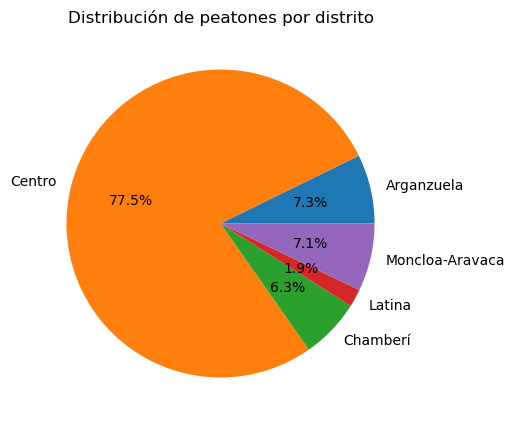

In [74]:
plt.figure(figsize=(5, 5))

plt.pie(peatones_distrito.values, labels=peatones_distrito.index, autopct="%1.1f%%")

plt.title("Distribución de peatones por distrito")

***Interpretación:*** Sin duda, el distrito `CENTRO` es el distrito con mayor número de peatones registrados.

### Gráficos: plot y scatter

Gráfico de líneas que tiene en el eje $x$ una variable temporal, categórica o numérica y en el eje $y$ una variable numérica.

Text(0, 0.5, 'Número de peatones')

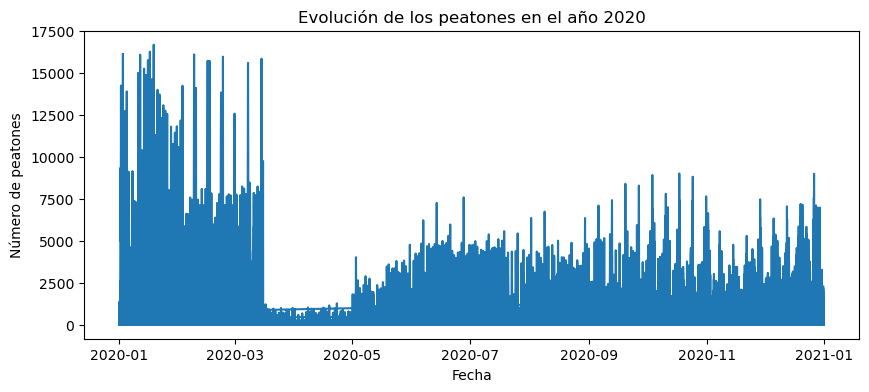

In [180]:
plt.figure(figsize=(10, 4))

plt.plot(df_1["FECHA"], df_1["PEATONES"])

plt.title("Evolución de los peatones en el año 2020")
plt.xlabel("Fecha")
plt.ylabel("Número de peatones")

***Interpretación:*** Hacia mediados de marzo se ve un claro descenso en el número de peatones, recuperandose progresivamente a partir de mayo alcanzando su máximo en julio. En agosto se observan algunos días con un número de peatones notablemente inferior y, a partir de septiembre, podemos observar unas "crestas" más acentuadas similares al comportamiento de febrero, lo que puede indicar que los fines de semana se incrementa notablemente el número de peatones (esto es una hipótesis).  

Veamos qué día se decrementa notablemente el número de peatones. 


(0.0, 10100.0)

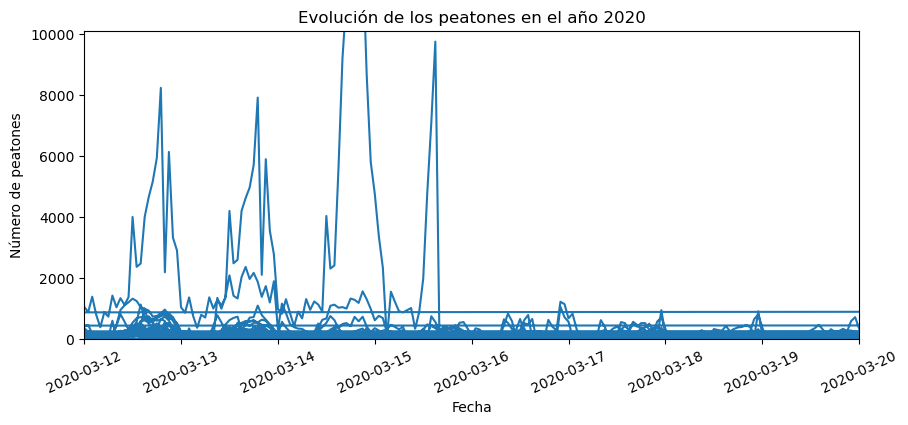

In [92]:
plt.figure(figsize=(10, 4))

plt.plot(df_1["FECHA"], df_1["PEATONES"])

plt.title("Evolución de los peatones en el año 2020")
plt.xlabel("Fecha")
plt.ylabel("Número de peatones")

plt.xticks(rotation=25)

plt.xlim(pd.Timestamp("2020-03-12"), pd.Timestamp("2020-03-20"))
plt.ylim(0, 10100)

***Interpretación:*** El día 16 de marzo es el primer día que apenas hay peatones por la calle.

***¿pero que són esas líneas horizontales que veo? No lo entiendo***

`plt.plot(df_1["FECHA"], df_1["PEATONES"])` representa cada fila del dataFrame como un punto y une cada punto con el siguiente mediante una línea. Si hay muchas observaciones con la misma fecha, se dibujan segmentos verticales que se superponen.

***Mejora 1:*** Aunque lo habitual es utilizar `plt.scatter()` para estudiar la relación entre dos variables numéricas, Matplotlib también permite utilizar fechas en el eje X de `plt.scatter()`.


(0.0, 10100.0)

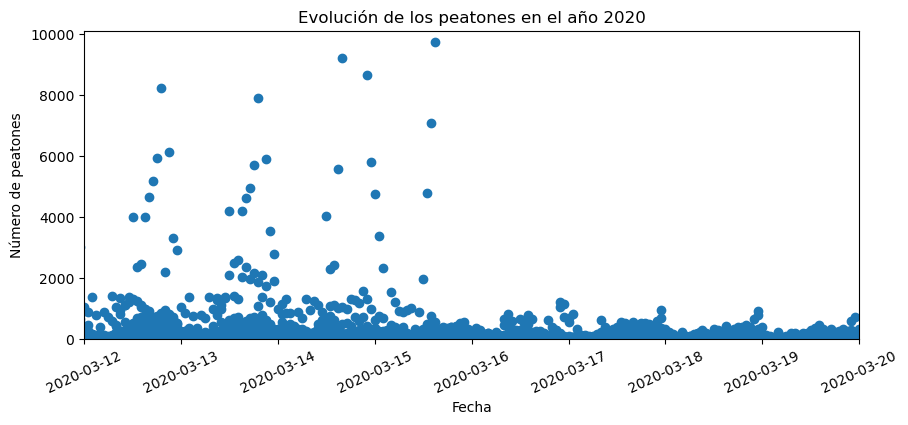

In [109]:
plt.figure(figsize=(10, 4))

plt.scatter(df_1["FECHA"], df_1["PEATONES"])

plt.title("Evolución de los peatones en el año 2020")
plt.xlabel("Fecha")
plt.ylabel("Número de peatones")

plt.xticks(rotation=25)

plt.xlim(pd.Timestamp("2020-03-12"), pd.Timestamp("2020-03-20"))
plt.ylim(0, 10100)

***Mejora 2:*** También podemos representar el **total** de peatones por fecha sin tener en cuenta la hora. Para ello necesito agrupar por el valor de FECHA ignorando la hora

```python
2020-03-15 00:00:00
2020-03-15 01:00:00
2020-03-15 02:00:00
2020-03-15 03:00:00
```

Fíjate que uso `.dt.normalize()` para convertir todas las horas a `00:00:00`.

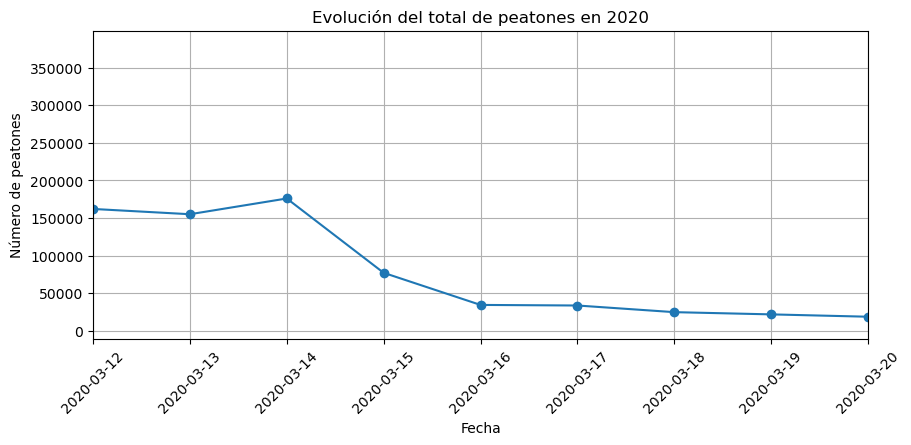

In [111]:
peatones_fecha = df_1.groupby(df_1["FECHA"].dt.normalize())["PEATONES"].sum()    #  OJO: uso .dt.normalize()

plt.figure(figsize=(10, 4))

plt.plot(peatones_fecha.index, peatones_fecha.values, marker="o")

plt.title("Evolución del total de peatones en 2020")
plt.xlabel("Fecha")
plt.ylabel("Número de peatones")

plt.xlim(pd.Timestamp("2020-03-12"), pd.Timestamp("2020-03-20"))

plt.xticks(rotation=45)
plt.grid("true")

***Interpretación:*** Entre los días 15 y 20 de marzo, el total de número de peatones por fechas es inferior a 50.000.

***¿hasta cuándo?*** Ampliamos la visión del eje x.


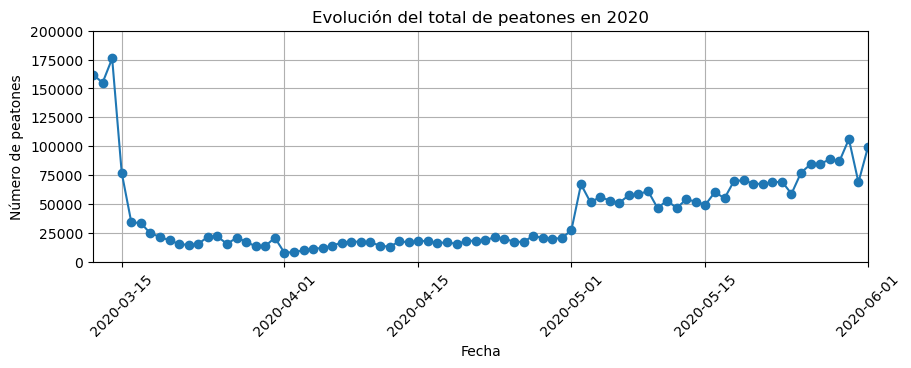

In [126]:
plt.figure(figsize=(10, 3))

plt.plot(peatones_fecha.index, peatones_fecha.values, marker="o")

plt.title("Evolución del total de peatones en 2020")
plt.xlabel("Fecha")
plt.ylabel("Número de peatones")

plt.xlim(pd.Timestamp("2020-03-12"), pd.Timestamp("2020-06-01"))
plt.ylim(0,200000)

plt.xticks(rotation=45)
plt.grid("true")

***Interpretación:*** A la pregunta de *¿hasta cuándo?* ¿hasta qué día el número de peatones es inferior a 50.000, la respuesta es el día 2 de mayo.



### Gráfico: bar

También podemos representar la evolución de los peatones con un diagrama de barras.

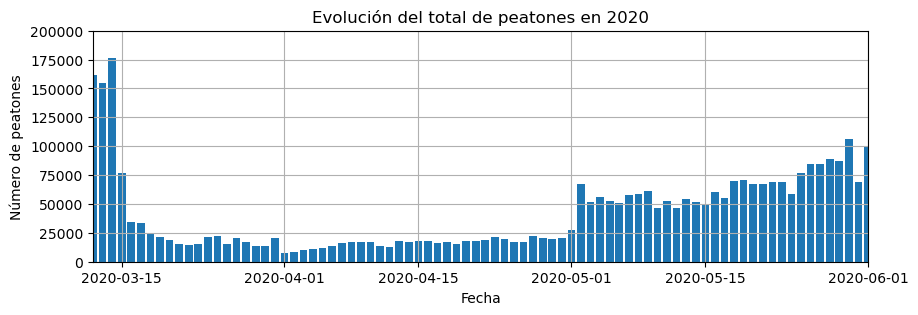

In [142]:
plt.figure(figsize=(10, 3))

plt.bar(peatones_fecha.index, peatones_fecha.values)

plt.title("Evolución del total de peatones en 2020")
plt.xlabel("Fecha")
plt.ylabel("Número de peatones")

plt.xlim(pd.Timestamp("2020-03-12"), pd.Timestamp("2020-06-01"))
plt.ylim(0,200000)
plt.grid("true")


La evolución total de los peatones del año 2020 completo también se puede hacer mensual haciendo el groupby por month.


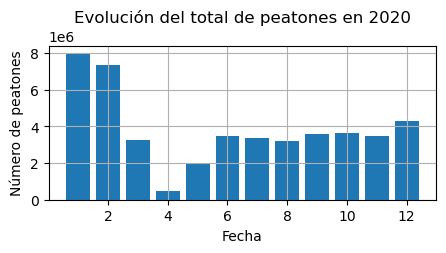

In [148]:
peatones_mes = df_1.groupby(df_1["FECHA"].dt.month)["PEATONES"].sum()   #  OJO: uso .dt.month, sin()

plt.figure(figsize=(5, 2))

plt.bar(peatones_mes.index, peatones_mes.values)

plt.title("Evolución del total de peatones en 2020")
plt.xlabel("Fecha")
plt.ylabel("Número de peatones")
plt.grid("true")

***Interpretación:*** el mes con menos peaotnes fue abril, seguido por mayo. En lo que queda de año no se alcazarón cifras anteriores a la pandemia.



### Gráfico: hist

Distribución de los peatones.

Cada valor de `PEATONES` es una observación del fichero. El *histograma* permite ver si la mayoría de las lecturas se concentran en valores pequeños o grandes. La distribución reúne distintas horas y puntos de aforo, por lo que no representa el total diario de la ciudad.

Text(0, 0.5, 'Frecuencia')

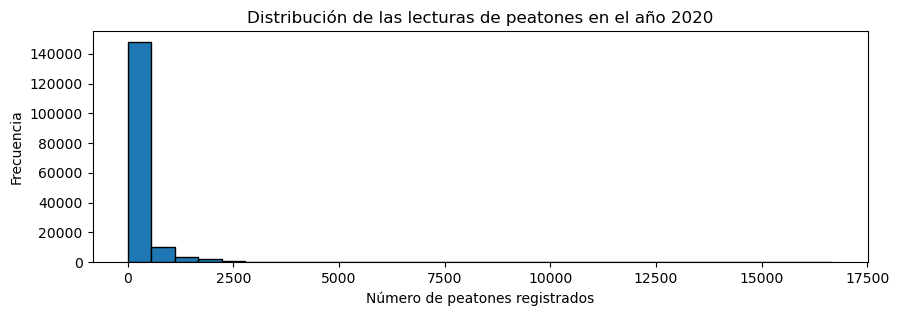

In [83]:
plt.figure(figsize=(10, 3))
plt.hist(df_1["PEATONES"], bins=30, edgecolor="black")
plt.title("Distribución de las lecturas de peatones en el año 2020")
plt.xlabel("Número de peatones registrados")
plt.ylabel("Frecuencia")


In [85]:
max(df_1["PEATONES"])

16673

In [ ]:
min(df_1["PEATONES"])

¿qué valores de peatones se repiten más?

In [86]:
df_1["PEATONES"].value_counts().head(10)

PEATONES
0    8043
1    3004
2    2374
3    2201
4    2058
5    1936
6    1845
8    1498
7    1497
9    1394
Name: count, dtype: int64

***Intrepretación:*** Más de 140,000 observaciones se concentran cerca del valor 0, que es un número alto teniendo en cuenta que hay 166896 observaciones en total. Además, hay alguna observación con el número de peatones que se aproxima a 175,000, pero es inferior. De hecho el valor máximo de la columna `PEATONES` es 16673.

### Gráfico: boxplot

Diagrama de caja y bigotes.

El diagrama de caja resume la distribución con la mediana, los cuartiles y los posibles valores atípicos. Los valores atípicos no tienen por qué ser errores: pueden corresponder a momentos o ubicaciones con mucho tránsito.

([<matplotlib.axis.XTick at 0x14e7592e0>], [Text(1, 0, '')])

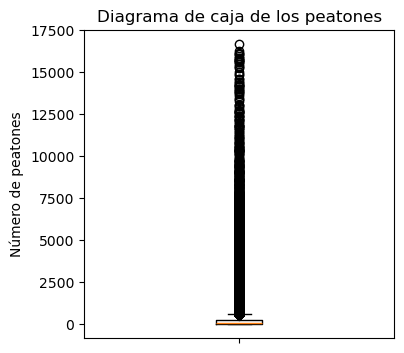

In [218]:
plt.figure(figsize=(4, 4))
plt.boxplot(df_1["PEATONES"])
plt.title("Diagrama de caja de los peatones")
plt.ylabel("Número de peatones")
plt.xticks([1], [""])  # muestra la etiqueta "" en la posición 1 del eje X

Como hay muchos valores atipicos no se aprecia.

La solución más sencilla es utilizar `showfliers=False`, que oculta los valores atípicos en el gráfico, pero no los elimina de los datos ni del cálculo de los cuartiles. De paso voy a darle un poco de color.

- `showfliers=False`: oculta los valores atípicos.
- `patch_artist=True`:	Permite colorear la caja.
- `boxprops`: Configura el color de la caja.
- `medianprops`: Destaca la mediana en rojo.
- `plt.grid(axis="y", alpha=0.5)` Añade una cuadrícula horizontal con transparencia 0,5.

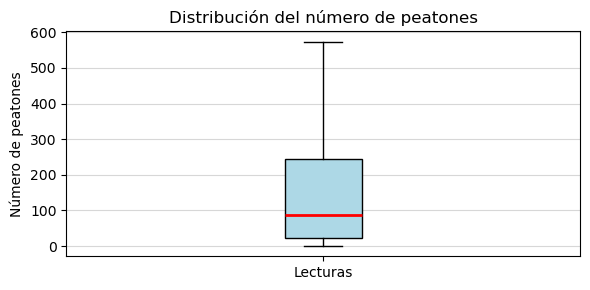

In [247]:
plt.figure(figsize=(6, 3))

plt.boxplot(
    df_1["PEATONES"].dropna(),
    showfliers = False,
    patch_artist = True,
    medianprops=dict(color="red", linewidth=2),
    boxprops = dict(facecolor="lightblue"),
)

plt.title("Distribución del número de peatones")
plt.ylabel("Número de peatones")
plt.xticks([1], ["Lecturas"])
plt.grid(axis="y", alpha=0.5)

plt.tight_layout()
plt.show()

## Calcular el total de peatones por día de la semana

Para analizar los peatones por día de la semana, necesitamos añadir una nueva columna con dichos datos.
Es decir, a partir de `FECHA`, crea una nueva columna llamada `DIA_SEMANA`.
El accesor `.dt` tiene un método `day_name()` que devuelve el nombre del día de la semana.

In [167]:
df_1["DIA_SEMANA"] = df_1["FECHA"].dt.day_name()


Si queremos los nombres en español, debemos traducir los nombres en inglés que devuelve `day_name()`. Para ello creamos un diccionario que relaciona cada nombre en inglés con su equivalente en español y aplicamos `map()`, que realiza la sustitución de forma vectorizada. Es más rápido que recorrer todas las filas con un bucle, especialmente en un conjunto de datos grande.

In [170]:
dias = {
    "Monday": "Lunes",
    "Tuesday": "Martes",
    "Wednesday": "Miércoles",
    "Thursday": "Jueves",
    "Friday": "Viernes",
    "Saturday": "Sábado",
    "Sunday": "Domingo"
}


df_1["DIA_SEMANA"] = df_1["FECHA"].dt.day_name()

for i in range(len(df_1)):
    df_1.loc[i, "DIA_SEMANA"] = dias[df_1.loc[i, "DIA_SEMANA"]]

# Esto tarda

In [171]:
peatones_dia = df_1.groupby("DIA_SEMANA")["PEATONES"].sum().sort_values(ascending=False)

peatones_dia

DIA_SEMANA
Sábado       8363292
Domingo      6882035
Viernes      6806128
Miércoles    6121263
Jueves       6112174
Lunes        5944647
Martes       5914144
Name: PEATONES, dtype: int64

### Gráfico: total de peatones por día de la semana

El gráfico de barras permite comparar los totales calculados. Para que el eje X contenga la semana de lunes a domingo hay que hacer:

```python
orden_dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
peatones_dia_ordenado = peatones_dia.reindex(orden_dias)
```

Además, hay que tener en cuenta que estamos trabajando con un `groupby`, por lo tanto en `plt.bar`debes usar 

- `peatones_dia_ordenado.index`: contiene los días de la semana, que aparecerán en el eje X.
- `peatones_dia_ordenado.values`: contiene los totales de peatones, que determinan la altura de las barras.

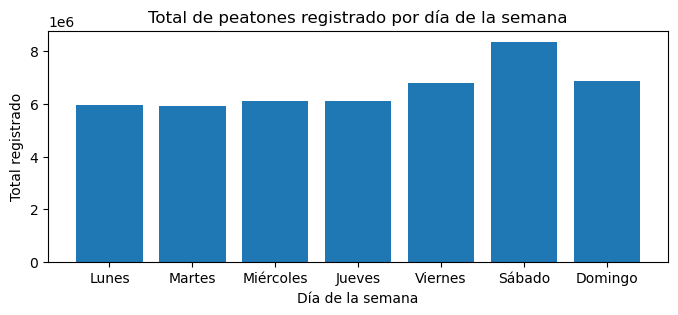

In [200]:
orden_dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
peatones_dia_ordenado = peatones_dia.reindex(orden_dias)

plt.figure(figsize=(8, 3))
plt.bar(peatones_dia_ordenado.index, peatones_dia_ordenado.values)
plt.title("Total de peatones registrado por día de la semana")
plt.xlabel("Día de la semana")
plt.ylabel("Total registrado")
#plt.xticks(rotation=25)
plt.show()

## Crear un DataFrame con el distrito Centro

In [175]:
df_Centro = df_1[df_1["DISTRITO"] == "Centro"].copy()



### Gráfico: total de peatones por día de la semana en el distrito Centro



In [61]:
peatones_dia_Centro = df_Centro.groupby("DIA_SEMANA")["PEATONES"].sum().sort_values(ascending=False)

peatones_dia_Centro

DIA_SEMANA
Sábado       6790629
Domingo      5434836
Viernes      5247852
Miércoles    4651721
Jueves       4643622
Lunes        4508395
Martes       4469403
Name: PEATONES, dtype: int64

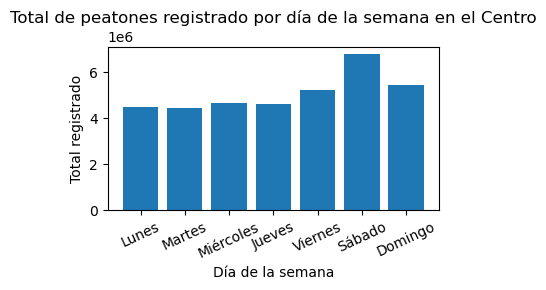

In [63]:
orden_dias_Centro = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
peatones_dia_Centro_ordenado = peatones_dia_Centro.reindex(orden_dias)

plt.figure(figsize=(4, 3))
plt.bar(peatones_dia_Centro_ordenado.index, peatones_dia_Centro_ordenado.values)
plt.title("Total de peatones registrado por día de la semana en el Centro")
plt.xlabel("Día de la semana")
plt.ylabel("Total registrado")
plt.xticks(rotation=25)

plt.show()

## Peatones de Madrid a las 23:00

Seleccionar las observaciones de `df_1` de las 23:00. 
Para ello filtra `df_1` utilizando la columna `HORA`.
Como `HORA` contiene objetos `datetime.time`, puedes comparar con una hora creada a partir de `"23:00"` o con `datetime.time(23, 0)`, es lo mismo.
Hago las dos versiones creando dos nuevos dataframes: `df_Madrid_23h_v1` y `df_Madrid_23h_v2`. El primero usa `"23:00"` y el segundo `datetime.time(23, 0)`. Después compruebo sus dimensiones y pregunto si son iguales con `df1.equals(df2)`.

In [212]:
df_Madrid_23h = df_1[df_1["HORA"] == pd.to_datetime("23:00", format="%H:%M").time()].copy()


### Gráfico 1: Peatones en Madrid a las 23:00 en el año 2020

ConversionError: Failed to convert value(s) to axis units: array([datetime.time(23, 0), datetime.time(23, 0), datetime.time(23, 0),
       ..., datetime.time(23, 0), datetime.time(23, 0),
       datetime.time(23, 0)], dtype=object)

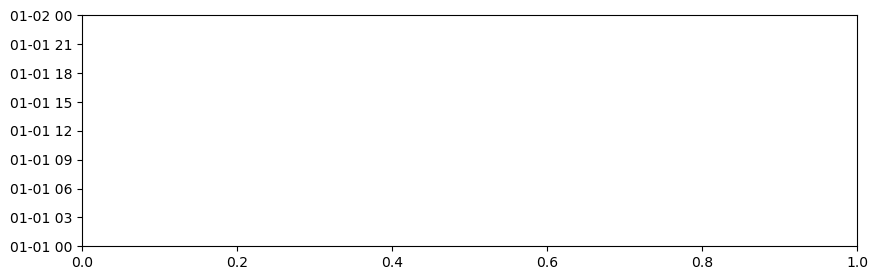

In [216]:
plt.figure(figsize=(10, 3))
plt.plot(df_Madrid_23h.index, df_Madrid_23h_v1.values, linewidth=1)
plt.title("Peatones a las 23:00")
plt.xlabel("Fecha")
plt.ylabel("Peatones")
plt.grid(True)

### Gráfico 2: distritos con número de peatones registrados a las 23:00

Este gráfico utiliza las observaciones cuya hora es 23:00. El total de cada distrito acumula los registros de esa hora a lo largo del periodo disponible; no representa una única noche.

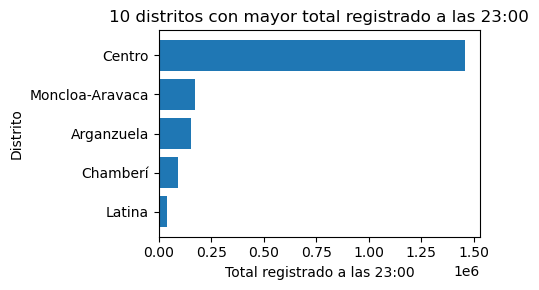

In [69]:
peatones_distrito_23h = (
    df_Madrid_23h_v1.groupby("DISTRITO")["PEATONES"]
    .sum()
    .nlargest(10)
    .sort_values()
)

plt.figure(figsize=(5, 3))
plt.barh(peatones_distrito_23h.index, peatones_distrito_23h.values)
plt.title("10 distritos con mayor total registrado a las 23:00")
plt.xlabel("Total registrado a las 23:00")
plt.ylabel("Distrito")



## Peatones de Centro a las 23:00

Seleccionar las observaciones de `df_Centro` de las 23:00. 

Observación: Necesitarás combinar las condiciones de distrito y hora si partes de `df_1`, pero aquí ya tenemos filtrado el distrito. Por esto, es importante partir de `df_Centro` y añadir la condición de que la hora sea `23:00`.

Después, observamos las filas y columnas de la tabla.

In [72]:
# df_Centro_23h = df_Centro[df_Centro["HORA"] == pd.to_datetime("23:00", format="%H:%M").time()].copy()
df_Centro_23h = df_Centro[df_Centro["HORA"] == datetime.time(23, 0)].copy()
df_Centro_23h.shape

(4758, 7)

### Gráfico: calles de Centro con más peatones a las 23:00

El gráfico permite comparar las direcciones del distrito Centro con mayor suma de lecturas registradas a las 23:00 durante el periodo disponible.

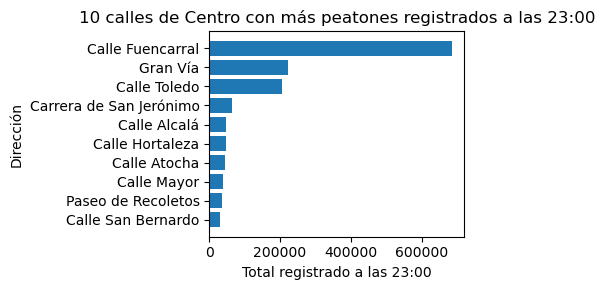

In [75]:
peatones_calle_centro_23h = (
    df_Centro_23h.groupby("DIRECCIÓN")["PEATONES"]
    .sum()
    .nlargest(10)
    .sort_values()
)

plt.figure(figsize=(5, 3))
plt.barh(peatones_calle_centro_23h.index, peatones_calle_centro_23h.values)
plt.title("10 calles de Centro con más peatones registrados a las 23:00")
plt.xlabel("Total registrado a las 23:00")
plt.ylabel("Dirección")



## Total de peatones de Madrid por mes

Para estudiar los totales por mes, primero creamos una nueva columna `MES` extrayendo el número de mes de `FECHA` mediante `.dt`, ya que la columna `FECHA` contiene valores de fecha y hora.


In [78]:
df_1["MES"] = df_1["FECHA"].dt.month



Ahora agrupamos y sumamos los peatones, es decir,  agrupamos por `MES` y seleccionamos la columna `PEATONES`.

¿Qué función de agregación necesitamos para obtener el total de peatones de cada mes?

Comprueba el resultado de la agrupación.
Deberías obtener un valor para cada uno de los meses disponibles.

In [81]:

peatones_mes = df_1.groupby("MES")["PEATONES"].sum()

print(peatones_mes)


MES
1     8006983
2     7361212
3     3241413
4      490313
5     1968095
6     3503517
7     3380743
8     3179427
9     3587082
10    3646475
11    3461438
12    4316985
Name: PEATONES, dtype: int64


### Gráfico: evolución del total mensual de peatones

El gráfico de líneas permite observar cómo cambia el total registrado a lo largo de los meses. Las sumas mensuales pueden estar influidas por los días disponibles y por la cantidad de puntos de aforo con datos; por sí solas no demuestran que la pandemia sea la causa de los cambios.

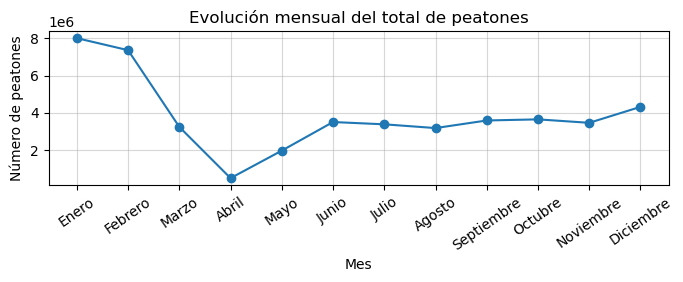

In [114]:
meses_ord = [ "Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio", "Julio", "Agosto",
    "Septiembre", "Octubre", "Noviembre", "Diciembre"
]

plt.figure(figsize=(8, 2))
plt.plot(peatones_mes.index, peatones_mes.values, marker="o")
plt.title("Evolución mensual del total de peatones")
plt.xlabel("Mes")
plt.ylabel("Número de peatones")
plt.xticks(range(1, 13),meses_ord,rotation=35)
plt.grid(True, alpha=0.5)  # transparencia


## Calcular el total de peatones en una fecha concreta y por distrito

Queremos saber cuántos peatones había en la calle, por ejemplo, el 15 de marzo del 2020. Para esto hay que seguir los siguientes pasos:

1. A partir del DataFrame df_1, seleccionar los registros del 15 de marzo de 2020 y dejarlos en un nuevo DataFrame `df_fecha`.

2. Calcular el total de peatones aplicando el método `sum()` a la variable `PEATONES`.

3. Calcular el total por distrito

In [183]:
# 1. Seleccionar los registros del 15 de marzo de 2020

fecha = pd.to_datetime("15/03/2020", dayfirst=True)

df_fecha = df_1[df_1["FECHA"].dt.date == fecha.date()].copy()

# 2. Calcular el total de peatones

total_peatones = df_fecha["PEATONES"].sum()

print("Total de peatones:", total_peatones, "\n")

# 3. Calcular el total por distrito

peatones_distrito = df_fecha.groupby("DISTRITO")["PEATONES"].sum()

peatones_distrito = peatones_distrito.sort_values(ascending=False)

print(peatones_distrito)


Total de peatones: 76945 

DISTRITO
Centro             56432
Chamberí            7329
Arganzuela          6234
Moncloa-Aravaca     3555
Latina              3395
Name: PEATONES, dtype: int64


### Gráfico 1: Número de peatones por distrito el 15 de marzo de 2020

Las barras horizontales comparan los totales de los distritos en la fecha elegida. Se muestran los diez distritos con mayor total para mantener legible el gráfico.

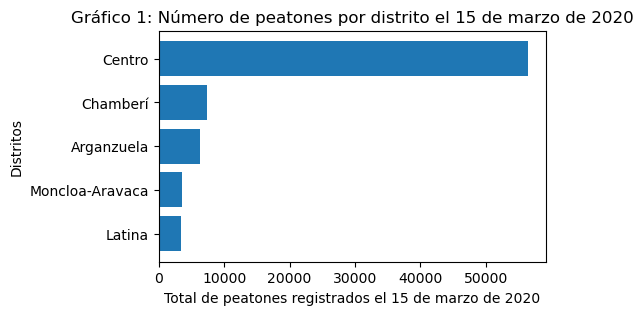

In [186]:
peatones_distrito_fecha_grafico = peatones_distrito.sort_values()

plt.figure(figsize=(5, 3))
plt.barh(peatones_distrito_fecha_grafico.index, peatones_distrito_fecha_grafico.values)
plt.title("Gráfico 1: Número de peatones por distrito el 15 de marzo de 2020")
plt.xlabel("Total de peatones registrados el 15 de marzo de 2020")
plt.ylabel("Distritos")

plt.show()

### Gráfico 2: Número de peatones por distrito el 15 de marzo de 2020


Text(0.5, 1.0, 'Número de peatones el 15/01/2020 por distrito')

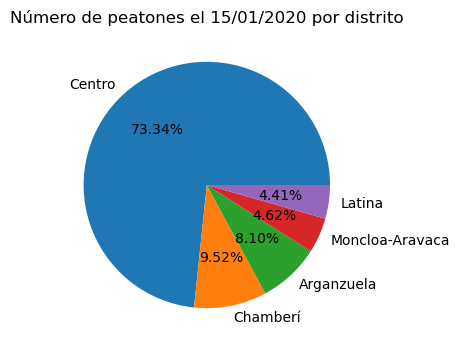

In [191]:
plt.figure(figsize=(4, 4))
plt.pie(peatones_distrito.values, labels=peatones_distrito.index, autopct="%1.2f%%")
plt.title("Número de peatones el 15/01/2020 por distrito")

## Las 10 calles con más peatones

Pasos:

1. A partir del DataFrame df_1, agrupa los registros por calle, utilizando la columna DIRECCIÓN.

2. Calcula el total de peatones registrados en cada calle.

3. Ordena las calles de mayor a menor número de peatones.

4. Muestra las 10 calles con mayor número total de peatones.


In [194]:
# 1. Calcular el total de peatones por calle

peatones_calle = df_1.groupby("DIRECCIÓN")["PEATONES"].sum()

# 2. Ordenar de mayor a menor

peatones_calle = peatones_calle.sort_values(ascending=False)

# 3. Seleccionar las 10 calles con más peatones

top_10 = peatones_calle.head(10)

print(top_10)


# Se puede hacer directamente en una instrucción
# pero hacemos 3 pasos para observar el proceso
# df_1.groupby("DIRECCION")["PEATONES"].sum().sort_values(ascending=False).head(10)

DIRECCIÓN
Calle Fuencarral                20192010
Gran Vía                         5617293
Calle Princesa                   3283849
Calle Toledo                     2821574
Plaza del Emperador Carlos V     2185960
Calle Génova                     1759394
Carrera de San Jerónimo          1215547
Ronda de Valencia                1160608
Alberto Aguilera                 1149314
Calle Atocha                     1046587
Name: PEATONES, dtype: int64


### Gráfico: las 10 calles con más peatones

Las barras horizontales ordenan las calles por el total acumulado de lecturas de `PEATONES` en el periodo. El formato horizontal resulta adecuado porque los nombres de las calles pueden ser largos.

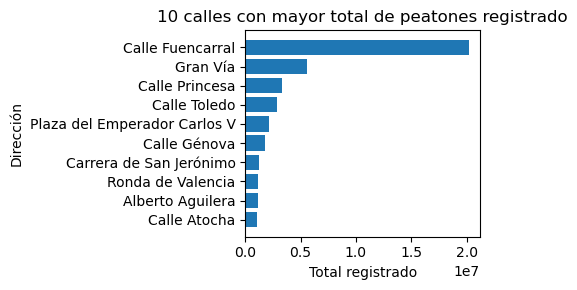

In [59]:
top_10_grafico = top_10.sort_values()

plt.figure(figsize=(5, 3))
plt.barh(top_10_grafico.index, top_10_grafico.values)
plt.title("Las 10 calles con mayor número de peatones")
plt.xlabel("Total registrado")
plt.ylabel("Dirección")

plt.show()

**Interpretación:** La *Calle Fuencarral* (20192010) es la más concurrida, según la disposición de los sensores, con una diferencia importante respecto a la segunda calle más concurrida, *Gran Vía* (5617293). El resto de calles decrecen más lentamente.



## ¿A qué hora hay más peatones?

Pasos:

1. Agrupa los registros por hora.

2. Calcula el total de peatones registrados en cada hora.

3. Ordena los resultados de mayor a menor.

4. Identifica la hora con mayor y menor número total de peatones.



In [61]:
df_1.columns

Index(['FECHA', 'HORA', 'PEATONES', 'DISTRITO', 'DIRECCIÓN', 'NÚMERO',
       'DIA_SEMANA', 'MES'],
      dtype='object')

In [62]:
df_1.groupby("HORA")["PEATONES"].sum().sort_values(ascending=False)

HORA
20:00:00    4469552
21:00:00    4169983
19:00:00    4013067
18:00:00    3304044
14:00:00    3059466
22:00:00    2906280
13:00:00    2815571
15:00:00    2751493
17:00:00    2732509
16:00:00    2488252
12:00:00    2398073
23:00:00    1911736
11:00:00    1650985
00:00:00    1253469
10:00:00    1217730
09:00:00     931989
01:00:00     846635
08:00:00     678473
02:00:00     592709
07:00:00     475331
03:00:00     426225
04:00:00     384638
05:00:00     335120
06:00:00     330353
Name: PEATONES, dtype: int64

### Gráfico: total de peatones registrado por hora del día

Para visualizar la evolución a lo largo de las 24 horas, ordenamos las horas cronológicamente (de 00:00 a 23:00), no por el tamaño de los totales. Los valores suman las observaciones de esa hora en todos los días y puntos de aforo disponibles.

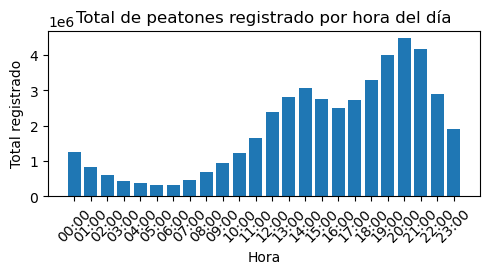

In [64]:
peatones_hora_grafico = df_1.groupby("HORA")["PEATONES"].sum().sort_index()
etiquetas_horas = [hora.strftime("%H:%M") for hora in peatones_hora_grafico.index]

plt.figure(figsize=(5, 3))
plt.bar(etiquetas_horas, peatones_hora_grafico.values)
plt.title("Total de peatones registrado por hora del día")
plt.xlabel("Hora")
plt.ylabel("Total registrado")
plt.xticks(rotation=45)

plt.show()